# Quadratic Modeling and Optimization

## General Settings

In [82]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from scipy.optimize import minimize
import seaborn as sns
import matplotlib.pyplot as plt

## Import and Prepare Data

In [83]:
processed_data_path = os.path.join(os.path.dirname(os.getcwd()), "..", "data", "processed")
input_data_path = os.path.join(processed_data_path, "input_data.csv")
output_data_avg_recovery_path = os.path.join(processed_data_path, "output_data_avg_recovery.csv")
output_data_avg_removal_path = os.path.join(processed_data_path, "output_data_avg_removal.csv")

df_input = pd.read_csv(input_data_path)
df_output_avg_recovery = pd.read_csv(output_data_avg_recovery_path)
df_output_avg_removal = pd.read_csv(output_data_avg_removal_path)

input_columns = ["Flow_C (l/min)", "Flow_P (l/min)", "Current_Limit_P (A)"]
output_column_recovery = ["Average Water Recovery (%)"]
output_column_removal = ["Average CO2 Removal (%)"]

X = df_input[input_columns].values
y_recovery = df_output_avg_recovery[output_column_recovery].values
y_removal = df_output_avg_removal[output_column_removal].values

## Quadratic Model

      1   x1        x2   x3  x1^2     x1 x2  x1 x3      x2^2     x2 x3  x3^2
0   1.0  0.4  0.454545  1.0  0.16  0.181818   0.40  0.206612  0.454545  1.00
1   1.0  0.2  0.272727  1.0  0.04  0.054545   0.20  0.074380  0.272727  1.00
2   1.0  0.1  0.090909  1.0  0.01  0.009091   0.10  0.008264  0.090909  1.00
3   1.0  0.0  0.000000  1.0  0.00  0.000000   0.00  0.000000  0.000000  1.00
4   1.0  0.6  0.636364  1.0  0.36  0.381818   0.60  0.404959  0.636364  1.00
5   1.0  0.4  0.454545  1.0  0.16  0.181818   0.40  0.206612  0.454545  1.00
6   1.0  0.5  0.545455  1.0  0.25  0.272727   0.50  0.297521  0.545455  1.00
7   1.0  0.6  0.636364  1.0  0.36  0.381818   0.60  0.404959  0.636364  1.00
8   1.0  0.7  0.727273  1.0  0.49  0.509091   0.70  0.528926  0.727273  1.00
9   1.0  0.8  0.818182  1.0  0.64  0.654545   0.80  0.669421  0.818182  1.00
10  1.0  0.9  0.909091  1.0  0.81  0.818182   0.90  0.826446  0.909091  1.00
11  1.0  1.0  1.000000  1.0  1.00  1.000000   1.00  1.000000  1.000000  1.00

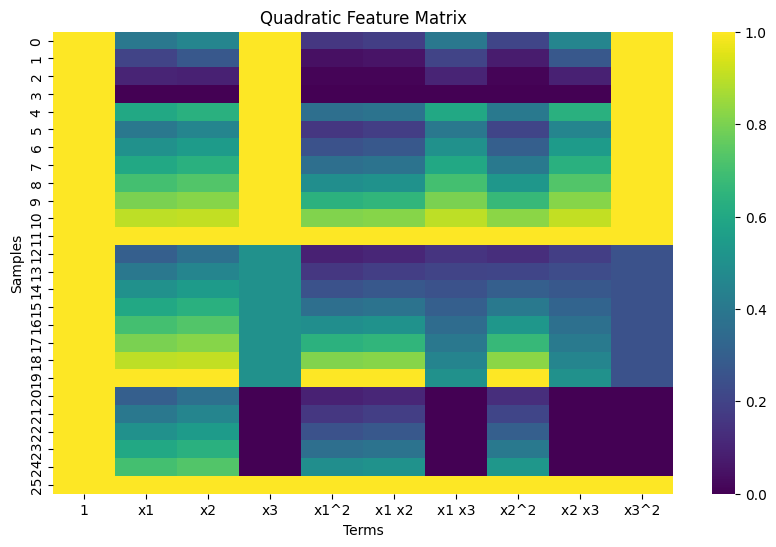

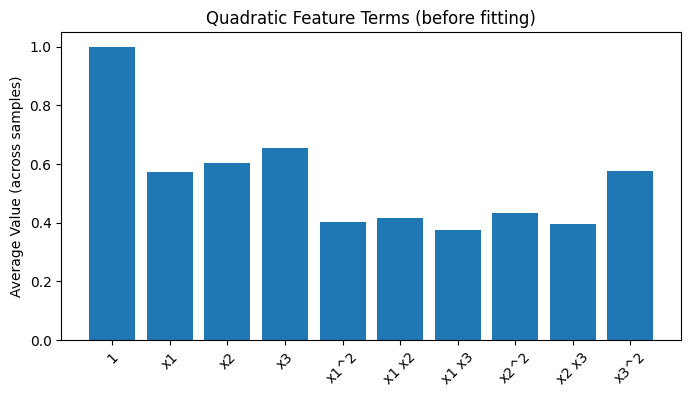

In [84]:
poly = PolynomialFeatures(degree=2, include_bias=True)
X_quad = poly.fit_transform(X)

# Feature names
feature_names = poly.get_feature_names_out(["x1", "x2", "x3"])

# Display as DataFrame
X_quad_df = pd.DataFrame(X_quad, columns=feature_names)
print(X_quad_df.head(30))

plt.figure(figsize=(10,6))
sns.heatmap(X_quad_df, annot=False, cmap='viridis')
plt.title("Quadratic Feature Matrix")
plt.xlabel("Terms")
plt.ylabel("Samples")
plt.show()

plt.figure(figsize=(8,4))
plt.bar(feature_names, np.mean(X_quad, axis=0))  
plt.xticks(rotation=45)
plt.ylabel("Average Value (across samples)")
plt.title("Quadratic Feature Terms (before fitting)")
plt.show()


## Model Fitting

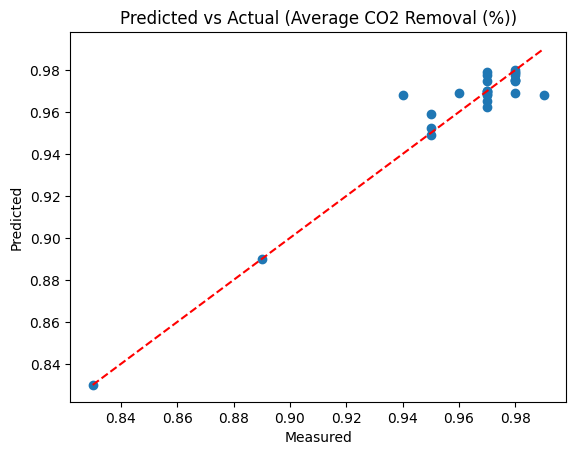

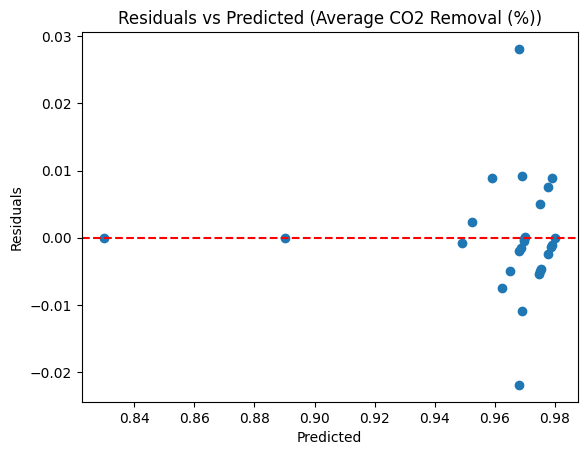

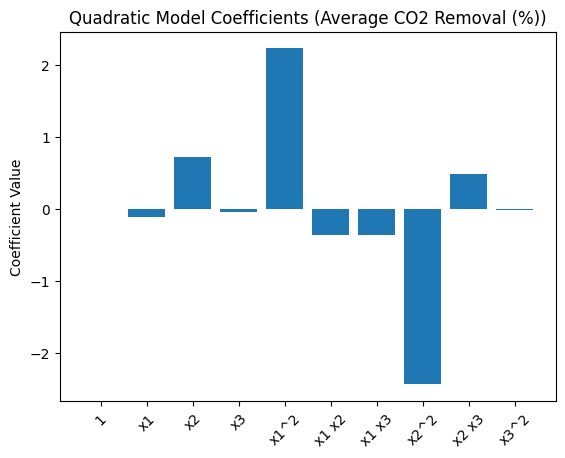

Average CO2 Removal (%)(x1, x2, x3) = 0.903 + (-0.113)*x1 + (0.719)*x2 + (-0.050)*x3 + (2.226)*x1^2 + (-0.371)*x1 x2 + (-0.367)*x1 x3 + (-2.439)*x2^2 + (0.483)*x2 x3 + (-0.022)*x3^2


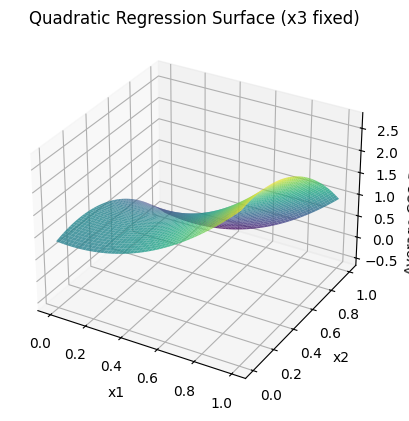

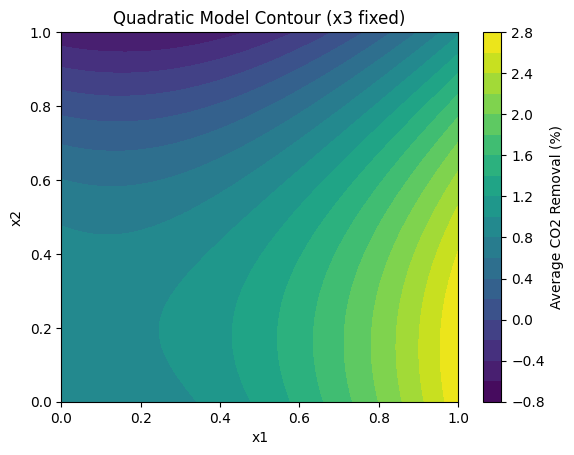

In [85]:
model = LinearRegression(fit_intercept=True, positive=False)
model.fit(X_quad, y_removal)

y_pred = model.predict(X_quad)

import matplotlib.pyplot as plt

for i, label in enumerate(["Average CO2 Removal (%)"]):
    plt.figure()
    plt.scatter(y_removal[:,i], y_pred[:,i])
    plt.plot([y_removal[:,i].min(), y_removal[:,i].max()], [y_removal[:,i].min(), y_removal[:,i].max()], 'r--')
    plt.xlabel("Measured")
    plt.ylabel("Predicted")
    plt.title(f"Predicted vs Actual ({label})")
    plt.show()

residuals = y_pred - y_removal
for i, label in enumerate(["Average CO2 Removal (%)"]):
    plt.figure()
    plt.scatter(y_pred[:,i], residuals[:,i])
    plt.axhline(0, color='r', linestyle='--')
    plt.xlabel("Predicted")
    plt.ylabel("Residuals")
    plt.title(f"Residuals vs Predicted ({label})")
    plt.show()

coef_names = X_quad_df.columns
for i, label in enumerate(["Average CO2 Removal (%)"]):
    plt.figure()
    plt.bar(coef_names, model.coef_[i])
    plt.xticks(rotation=45)
    plt.ylabel("Coefficient Value")
    plt.title(f"Quadratic Model Coefficients ({label})")
    plt.show()

for i, label in enumerate(["Average CO2 Removal (%)"]):
    eq = f"{label}(x1, x2, x3) = "
    terms = []
    # intercept
    terms.append(f"{model.intercept_[i]:.3f}")
    # coefficients * feature names
    for coef, name in zip(model.coef_[i], feature_names):
        if name == "1":  # skip bias term
            continue
        terms.append(f"({coef:.3f})*{name}")
    eq += " + ".join(terms)
    print(eq)

# Choose two variables to plot (x1, x2), fix x3 at its mean
x1_range = np.linspace(X[:,0].min(), X[:,0].max(), 50)
x2_range = np.linspace(X[:,1].min(), X[:,1].max(), 50)
x3_fixed = np.mean(X[:,2])

X1, X2 = np.meshgrid(x1_range, x2_range)
X_plot = np.column_stack([X1.ravel(), X2.ravel(), np.full(X1.ravel().shape, x3_fixed)])

# Transform with quadratic features
X_plot_quad = poly.transform(X_plot)
y_plot = model.predict(X_plot_quad)  # shape (2500, n_outputs)

# Example for Output 1
Y1 = y_plot[:,0].reshape(X1.shape)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X1, X2, Y1, cmap='viridis', alpha=0.8)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("Average CO2 Removal (%)")
ax.set_title("Quadratic Regression Surface (x3 fixed)")
plt.show()

plt.contourf(X1, X2, Y1, levels=20, cmap='viridis')
plt.colorbar(label="Average CO2 Removal (%)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Quadratic Model Contour (x3 fixed)")
plt.show()

## Model Validation: LOOCV

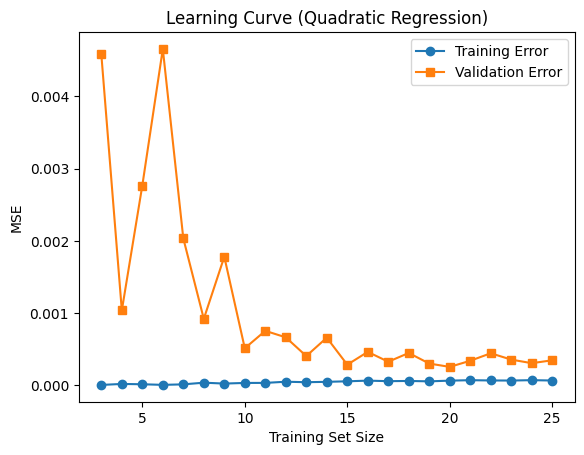

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

poly = PolynomialFeatures(degree=2, include_bias=True)

train_sizes = np.arange(3, len(X))   # start with at least 3 points
train_errors = []
val_errors = []

# Repeat experiment multiple times per size for stability
n_repeats = 20

for m in train_sizes:
    mse_train = []
    mse_val = []
    
    for _ in range(n_repeats):
        # Random split (80% train, 20% validation, but only m samples in train)
        X_train_full, X_val, Y_train_full, Y_val = train_test_split(X, y_removal, test_size=0.2)
        X_train = X_train_full[:m]
        Y_train = Y_train_full[:m]
        
        # Quadratic features
        X_train_quad = poly.fit_transform(X_train)
        X_val_quad = poly.transform(X_val)
        
        # Train model
        model = LinearRegression().fit(X_train_quad, Y_train)
        
        # Predict
        y_train_pred = model.predict(X_train_quad)
        y_val_pred = model.predict(X_val_quad)
        
        # Compute average MSE across outputs
        mse_train.append(mean_squared_error(Y_train, y_train_pred))
        mse_val.append(mean_squared_error(Y_val, y_val_pred))
    
    # Store mean errors
    train_errors.append(np.mean(mse_train))
    val_errors.append(np.mean(mse_val))

# --- Plot ---
plt.plot(train_sizes, train_errors, label="Training Error", marker="o")
plt.plot(train_sizes, val_errors, label="Validation Error", marker="s")
plt.xlabel("Training Set Size")
plt.ylabel("MSE")
plt.title("Learning Curve (Quadratic Regression)")
plt.legend()
plt.show()

📊 Validation results for Average CO2 Removal (%):
   MSE = 0.0003
   MAE = 0.0107
   R²  = 0.7274



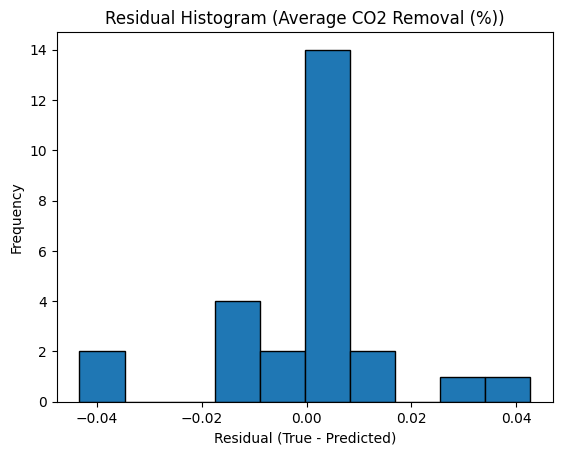

In [87]:


import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneOut
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Example: input X, output Y (n_samples x 3 features, n_samples x 2 outputs)
  # replace with your data
  # replace with your data

poly = PolynomialFeatures(degree=2, include_bias=True)
loo = LeaveOneOut()

y_true = []
y_pred_loocv = []

for train_idx, test_idx in loo.split(X):
    # Split
    X_train, X_test = X[train_idx], X[test_idx]
    Y_train, Y_test = y_removal[train_idx], y_removal[test_idx]
    
    # Quadratic expansion
    X_train_quad = poly.fit_transform(X_train)
    X_test_quad = poly.transform(X_test)
    
    # Fit model
    model = LinearRegression().fit(X_train_quad, Y_train)
    
    # Predict left-out sample
    y_pred = model.predict(X_test_quad)
    
    # Store results
    y_true.append(Y_test.flatten())
    y_pred_loocv.append(y_pred.flatten())

# Convert to arrays
y_true = np.array(y_true)          # shape (n_samples, n_outputs)
y_pred_loocv = np.array(y_pred_loocv)

# --- Metrics ---
for i, label in enumerate(["Average CO2 Removal (%)"]):
    mse = mean_squared_error(y_true[:, i], y_pred_loocv[:, i])
    mae = mean_absolute_error(y_true[:, i], y_pred_loocv[:, i])
    r2 = r2_score(y_true[:, i], y_pred_loocv[:, i])
    
    print(f"📊 Validation results for {label}:")
    print(f"   MSE = {mse:.4f}")
    print(f"   MAE = {mae:.4f}")
    print(f"   R²  = {r2:.4f}\n")
    
    # Residuals
    residuals = y_true[:, i] - y_pred_loocv[:, i]
    
    # Histogram of residuals
    plt.figure()
    plt.hist(residuals, bins=10, edgecolor='black')
    plt.xlabel("Residual (True - Predicted)")
    plt.ylabel("Frequency")
    plt.title(f"Residual Histogram ({label})")
    plt.show()



In [90]:
def objective(x):
    x = np.array(x).reshape(1, -1)           # shape (1,3)
    x_quad = poly.transform(x)               # quadratic features
    y_pred = model.predict(X_quad)[0, 0]     # single output
    return -y_pred 

bounds = [(X[:,0].min(), X[:,0].max()),
          (X[:,1].min(), X[:,1].max()),
          (X[:,2].min(), X[:,2].max())]

# Try multiple initial guesses
best_val = -np.inf
best_x = None
for x0 in [X.mean(axis=0), X.min(axis=0), X.max(axis=0)]:
    res = minimize(objective, x0, bounds=bounds, method='L-BFGS-B')
    if -res.fun > best_val:
        best_val = -res.fun
        best_x = res.x

print("Optimal input:", best_x)
print("Predicted maximum output:", best_val)

Optimal input: [0.57307692 0.6048951  0.65384615]
Predicted maximum output: 0.9679787269500292
